In [ ]:
#Task 3: Car Price Prediction with Machine Learning
"""Oasis Infobyte (OIBSIP) – Data Science Internship
1. Introduction
Car Price Prediction is a machine learning project that predicts the selling price of used cars based on features such as brand, age, mileage, fuel type, and transmission."""

In [ ]:
"""2. Objective
To predict used-car selling prices using machine learning.
To clean and analyze the dataset.
To train and compare regression models.
To evaluate performance using MAE, RMSE, and R² score."""

In [ ]:
"""3. Dataset
The project uses a publicly available used-car dataset from Kaggle, such as the CarDekho Vehicle Dataset.
Features: Car name, manufacturing year, selling price, kilometers driven, fuel type, transmission, and owner details."""

In [ ]:
"""4. Tools and Technology
1.Python: Programming language.
2.Pandas & NumPy: Data cleaning and analysis.
3.Matplotlib & Seaborn: Data visualization.
4.Scikit-learn: Machine learning models and evaluation.
5.Jupyter Notebook / Google Colab: Coding environment.
6.GitHub: Project storage and sharing."""

In [ ]:
"""5. Project Workflow
1.Collect the dataset.
2.Clean missing values and duplicates.
3.Perform feature engineering and EDA.
4.Encode categorical variables.
5.Split data into training and testing sets.
6.Train Linear Regression and Random Forest models.
7.Evaluate models using MAE, RMSE, and R².
8.Visualize feature importance and document results."""

In [ ]:
"""6. Expected Outcome
1.A cleaned and analyzed dataset.
2.Visualizations showing car-price patterns.
3.Two trained regression models.
4.Performance comparison to identify the better model.
5.A machine learning model capable of predicting used-car selling prices."""

In [1]:
#Step 1: Import Required Libraries
# Import libraries for data analysis
import pandas as pd
import numpy as np

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Import regression models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [13]:
#Step 2: Upload and Load the Dataset
df = pd.read_csv("/content/cardekho.csv")

In [3]:
# Display first five rows
display(df.head())

# Display last five rows
display(df.tail())

# Check number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("Column names:")
print(df.columns.tolist())

# Check data types and non-null values
df.info()

# Statistical summary
display(df.describe(include="all"))

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.50,1197.0,82.85,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493.0,110,5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.30,1248.0,73.9,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57,1396.0,70,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57,1396.0,70,5.0


Dataset shape: (8128, 12)
Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(3)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
count,8128,8128.000000,8.128000e+03,8.128000e+03,8128,8128,8128,8128,7907.000000,7907.000000,7913,7907.000000
unique,2058,NaN,NaN,NaN,4,3,2,5,NaN,NaN,320,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,NaN,NaN,74,NaN
freq,129,NaN,NaN,NaN,4402,6766,7078,5289,NaN,NaN,377,NaN
mean,NaN,2013.804011,6.382718e+05,6.981951e+04,NaN,NaN,NaN,NaN,19.418783,1458.625016,NaN,5.416719
std,NaN,4.044249,8.062534e+05,5.655055e+04,NaN,NaN,NaN,NaN,4.037145,503.916303,NaN,0.959588
min,NaN,1983.000000,2.999900e+04,1.000000e+00,NaN,NaN,NaN,NaN,0.000000,624.000000,NaN,2.000000
25%,NaN,2011.000000,2.549990e+05,3.500000e+04,NaN,NaN,NaN,NaN,16.780000,1197.000000,NaN,5.000000
50%,NaN,2015.000000,4.500000e+05,6.000000e+04,NaN,NaN,NaN,NaN,19.300000,1248.000000,NaN,5.000000
75%,NaN,2017.000000,6.750000e+05,9.800000e+04,NaN,NaN,NaN,NaN,22.320000,1582.000000,NaN,5.000000


In [4]:
#Step 3: Data Cleaning
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

print("\nDataset shape after removing duplicates:", df.shape)


Missing values:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

Duplicate rows: 1202

Dataset shape after removing duplicates: (6926, 12)


In [5]:
# Make column names lowercase and replace spaces with underscores
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Rename common variations to standard names
rename_columns = {
    "selling_price_inr": "selling_price",
    "price": "selling_price",
    "kms_driven": "km_driven",
    "kilometers_driven": "km_driven",
    "mileage_kmpl": "mileage",
    "fuel_type": "fuel",
    "transmission_type": "transmission",
    "car_name": "name",
    "brand_name": "name",
    "manufacturing_year": "year"
}

df = df.rename(columns={
    old: new
    for old, new in rename_columns.items()
    if old in df.columns and new not in df.columns
})

print("Updated columns:")
print(df.columns.tolist())

Updated columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage_km_ltr_kg', 'engine', 'max_power', 'seats']


In [6]:
# Clean text columns and standardize capitalization
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

    # Treat empty strings and common missing-value labels as missing
    df[col] = df[col].replace(
        r"(?i)^(|nan|none|null|na|n/a)$",
        pd.NA,
        regex=True
    )

# Standardize selected categorical columns
categorical_columns = [
    "fuel",
    "transmission",
    "seller_type",
    "owner"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].str.lower()

print("Categorical values standardized.")

Categorical values standardized.


In [7]:
# Convert relevant columns to numeric where possible
numeric_columns = [
    "year",
    "selling_price",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Numeric columns converted.")

Numeric columns converted.


In [8]:
# Selling price is the target variable
if "selling_price" not in df.columns:
    raise ValueError(
        "Target column 'selling_price' not found. "
        "Check your dataset's column names."
    )

# Remove rows without a valid selling price
df = df.dropna(subset=["selling_price"]).copy()

# Remove zero or negative selling prices
df = df[df["selling_price"] > 0].copy()

print("Dataset shape after target cleaning:", df.shape)

Dataset shape after target cleaning: (6926, 12)


In [9]:
#Step 4: Feature Engineering
# Calculate car age using the current year
CURRENT_YEAR = pd.Timestamp.now().year

if "year" in df.columns:
    df["year"] = pd.to_numeric(df["year"], errors="coerce")

    # Replace implausible manufacturing years with missing values
    df.loc[
        (df["year"] < 1950) | (df["year"] > CURRENT_YEAR),
        "year"
    ] = np.nan

    df["car_age"] = CURRENT_YEAR - df["year"]

print(df[["year", "car_age"]].head()
      if "year" in df.columns else "Year column unavailable.")

     year  car_age
0  2014.0     12.0
1  2014.0     12.0
2  2006.0     20.0
3  2010.0     16.0
4  2007.0     19.0


In [10]:
#Extract Car Brand
if "name" in df.columns:
    # Extract the first word from the car name
    df["brand"] = (
        df["name"]
        .str.strip()
        .str.split()
        .str[0]
        .str.lower()
    )

    print("Car brands extracted successfully.")

    print(df[["name", "brand"]].head())
else:
    print(
        "No 'name' column found. "
        "Brand extraction will be skipped."
    )

Car brands extracted successfully.
                           name    brand
0        Maruti Swift Dzire VDI   maruti
1  Skoda Rapid 1.5 TDI Ambition    skoda
2      Honda City 2017-2020 EXi    honda
3     Hyundai i20 Sportz Diesel  hyundai
4        Maruti Swift VXI BSIII   maruti


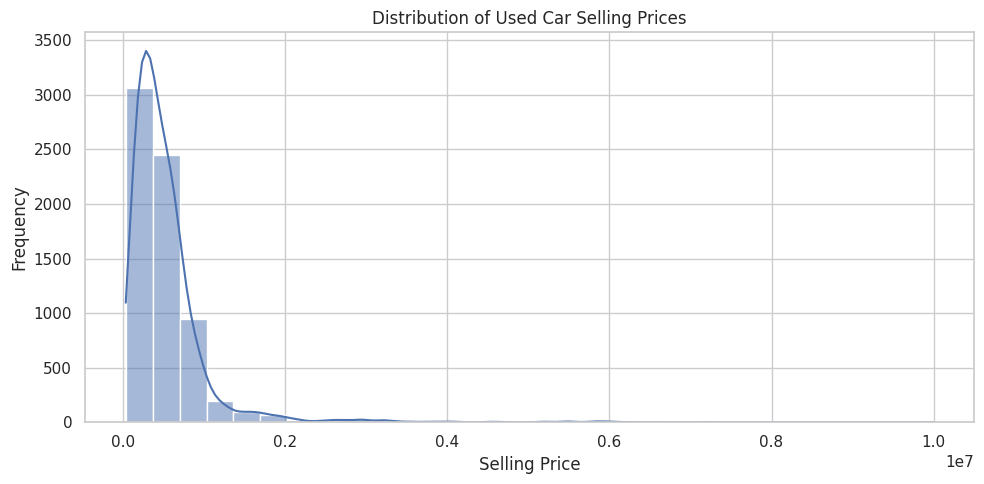

In [11]:
# Step 5: Exploratory Data Analysis (EDA)
#Selling Price Distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="selling_price",
    bins=30,
    kde=True
)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

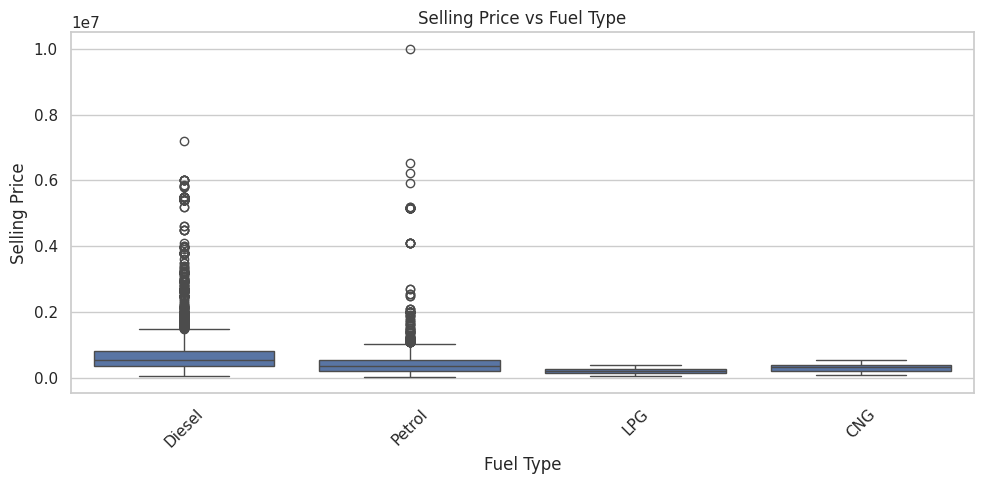

In [14]:
#Price vs Fuel Type
if "fuel" in df.columns:
    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x="fuel",
        y="selling_price"
    )

    plt.title("Selling Price vs Fuel Type")
    plt.xlabel("Fuel Type")
    plt.ylabel("Selling Price")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()
else:
    print("Fuel column not available.")

In [15]:
# Price vs Car Age
if "car_age" in df.columns:
    plot_df = df.dropna(subset=["car_age", "selling_price"])

    plt.figure(figsize=(10, 5))

    sns.scatterplot(
        data=plot_df,
        x="car_age",
        y="selling_price",
        alpha=0.6
    )

    plt.title("Selling Price vs Car Age")
    plt.xlabel("Car Age (Years)")
    plt.ylabel("Selling Price")

    plt.tight_layout()
    plt.show()
else:
    print("Car age feature unavailable.")

Car age feature unavailable.


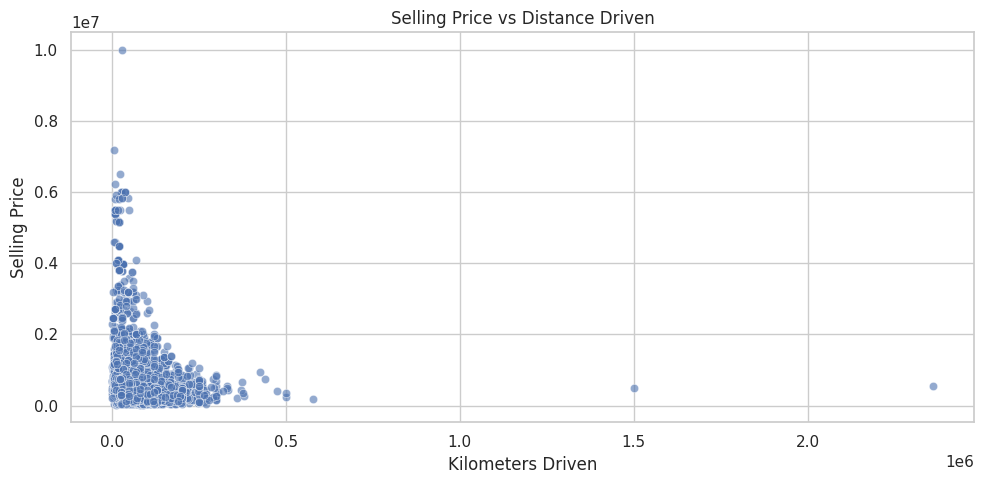

In [16]:
#Price vs Mileage
if "km_driven" in df.columns:
    plot_df = df.dropna(subset=["km_driven", "selling_price"])

    plt.figure(figsize=(10, 5))

    sns.scatterplot(
        data=plot_df,
        x="km_driven",
        y="selling_price",
        alpha=0.6
    )

    plt.title("Selling Price vs Distance Driven")
    plt.xlabel("Kilometers Driven")
    plt.ylabel("Selling Price")

    plt.tight_layout()
    plt.show()
else:
    print("Kilometers driven column unavailable.")

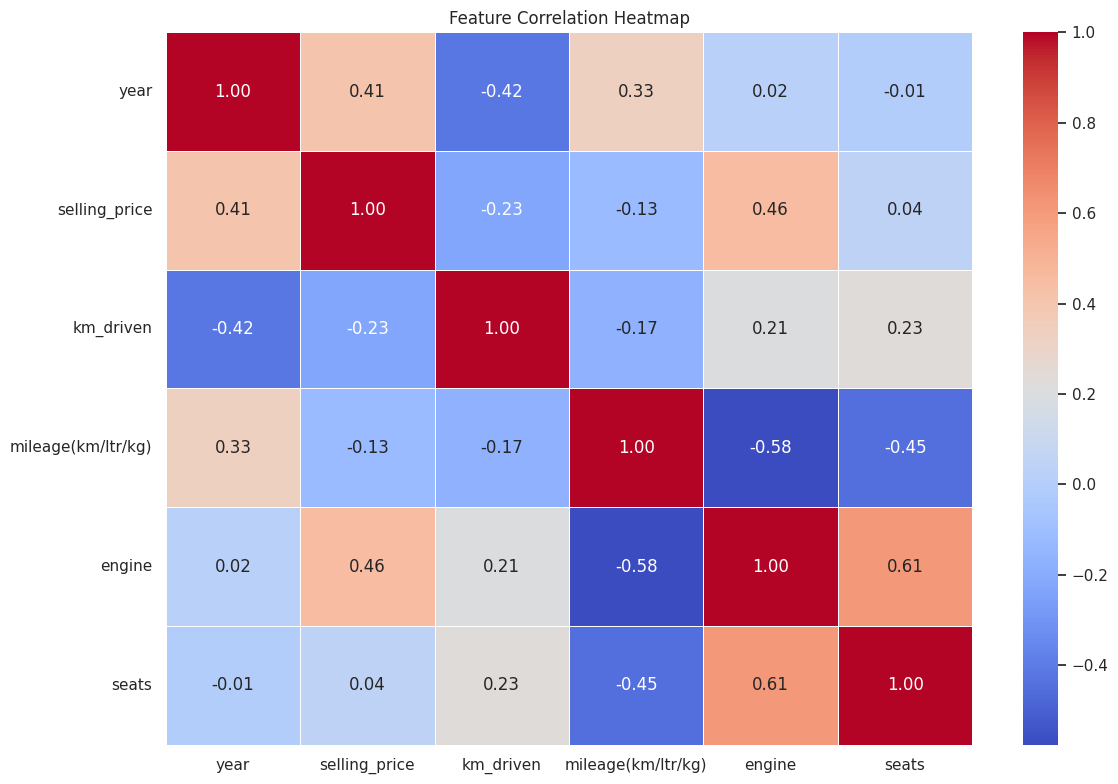

In [17]:
#Step 6 : Feature Correlation Heatmap
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlations
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

In [37]:
#Select Available Features
# Start with useful features
candidate_features = [
    "brand",
    "car_age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats",
    "fuel",
    "transmission",
    "seller_type",
    "owner"
]

# Keep only features that exist in the dataset
features = [
    col for col in candidate_features
    if col in df.columns
]

if not features:
    raise ValueError(
        "No expected feature columns found. "
        "Inspect your dataset and update candidate_features."
    )

X = df[features].copy()
y = df["selling_price"].copy()

print("Features used:")
print(features)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features used:
['km_driven', 'engine', 'max_power', 'seats', 'fuel', 'transmission', 'seller_type', 'owner']

Feature shape: (8128, 8)
Target shape: (8128,)


,km_driven,engine,max_power,seats,fuel,transmission,seller_type,owner
0,145500,1248.0,74,5.0,Diesel,Manual,Individual,First Owner
1,120000,1498.0,103.52,5.0,Diesel,Manual,Individual,Second Owner
2,140000,1497.0,78,5.0,Petrol,Manual,Individual,Third Owner
3,127000,1396.0,90,5.0,Diesel,Manual,Individual,First Owner
4,120000,1298.0,88.2,5.0,Petrol,Manual,Individual,First Owner


In [23]:
#Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 6502
Testing samples: 1626


In [24]:
#Step 8 :Encode Categorical Variables and Handle Missing Values
# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Numerical features: ['km_driven', 'engine', 'seats']
Categorical features: ['max_power', 'fuel', 'transmission', 'seller_type', 'owner']
Preprocessing pipeline created successfully.


In [25]:
#Step 9 : Train Regression Model
# Create the Linear Regression pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Predict prices
linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [27]:
#Train Random Forest Regressor
# Create the Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Predict prices
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [28]:
#Step 10 : Evaluate Both Model
#Calculate Evaluation Metrics
def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,302166.424,506131.628,0.609
1,Random Forest,106273.876,212729.204,0.931


In [29]:
#Identify the Best Model
# Choose the model with the lowest RMSE
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

if best_model_name == "Linear Regression":
    best_model = linear_model
    best_predictions = linear_predictions
else:
    best_model = random_forest_model
    best_predictions = rf_predictions

print("Best model based on test RMSE:", best_model_name)

print("\nBest model evaluation:")
print(
    results_df[
        results_df["Model"] == best_model_name
    ].round(3).to_string(index=False)
)

Best model based on test RMSE: Random Forest

Best model evaluation:
        Model        MAE       RMSE  R2 Score
Random Forest 106273.876 212729.204     0.931


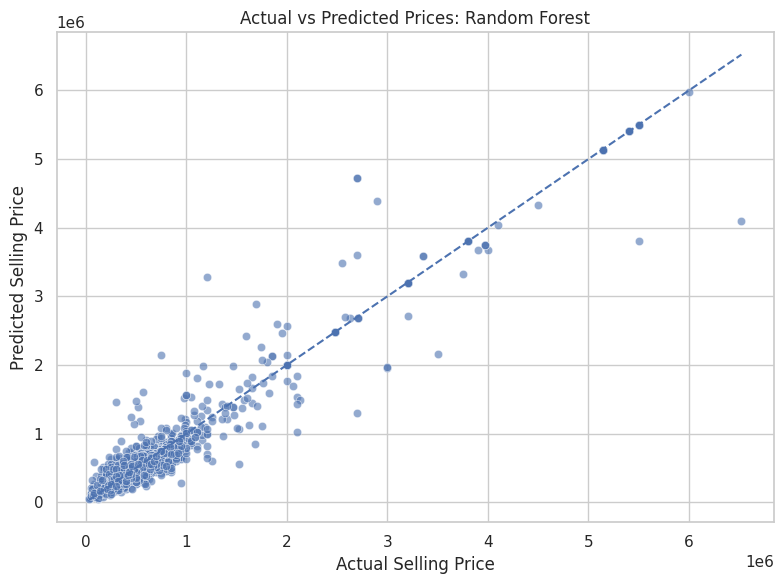

In [30]:
#Step 11 : Actual V/S Predicted Prices
#Actual vs Predicted Prices
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.6
)

# Draw the ideal prediction line
minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Prices: {best_model_name}")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.tight_layout()
plt.show()

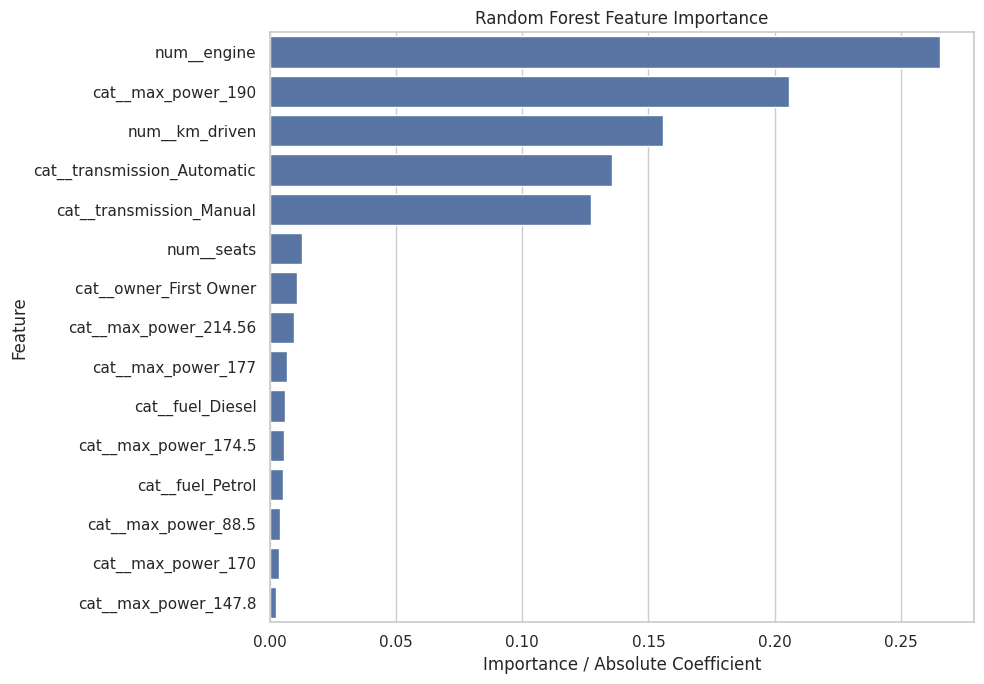

,Feature,Importance
1,num__engine,0.265660
135,cat__max_power_190,0.205756
0,num__km_driven,0.155699
315,cat__transmission_Automatic,0.135509
316,cat__transmission_Manual,0.127170
2,num__seats,0.012698
320,cat__owner_First Owner,0.010806
147,cat__max_power_214.56,0.009505
119,cat__max_power_177,0.007021
312,cat__fuel_Diesel,0.005965


In [39]:
#Step 12 : Feature Importance Chart
# Extract the fitted preprocessing pipeline
fitted_preprocessor = best_model.named_steps["preprocessor"]

# Obtain feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract importance values from the selected model
if best_model_name == "Random Forest":
    importance_values = (
        best_model.named_steps["model"].feature_importances_
    )
    importance_label = "Random Forest Feature Importance"

else:
    coefficients = best_model.named_steps["model"].coef_

    # Absolute coefficients indicate magnitude, not causal importance
    importance_values = np.abs(coefficients)
    importance_label = "Absolute Linear Regression Coefficients"


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title(importance_label)
plt.xlabel("Importance / Absolute Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

display(importance_df)

In [31]:
#Step 13 : Make a Prediction for a New Car
# Select one car from the test dataset
sample_car = X_test.iloc[[0]]

# Predict its selling price
predicted_price = best_model.predict(sample_car)[0]

actual_price = y_test.iloc[0]

print("Car details:")
display(sample_car)

print(f"Actual selling price: ₹{actual_price:,.2f}")
print(f"Predicted selling price: ₹{predicted_price:,.2f}")

print(
    f"Absolute prediction error: "
    f"₹{abs(actual_price - predicted_price):,.2f}"
)

Car details:


,km_driven,engine,max_power,seats,fuel,transmission,seller_type,owner
1971,110000,1493.0,100,5.0,Petrol,Manual,Individual,Third Owner


Actual selling price: ₹198,000.00
Predicted selling price: ₹168,453.66
Absolute prediction error: ₹29,546.34


In [33]:
#Step 14 : Save The Trained Model
#Save the Trained Model
import joblib

# Save the best-performing model pipeline
joblib.dump(
    best_model,
    "car_price_prediction_model.pkl"
)

print("Model saved successfully!")
from google.colab import files

files.download("car_price_prediction_model.pkl")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
#Save the Model Evaluation Results
# First save the DataFrame to a CSV file
results_df.to_csv("model_evaluation_results.csv", index=False)

# Now download the saved file
from google.colab import files
files.download("model_evaluation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
"""Conclusion
This project uses machine learning to predict used-car prices, identify important price factors, and compare regression models to find the best-performing model."""